In [1]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot  as plt

# Turbulence vs aliasing temporal PSDs (rMod 0, 2" pyramid FoV, no lag)

Runs of `config/aoeb/e2e/psd_compare.py` (`psd_compare.yml` on `ristretto_main.yml`): frozen-flow 10-layer ristretto atmosphere, 0.9", 8 s at
2 kHz, noiseless unmodulated pyramids 48x48 at 900 nm (VIS) and 1300 nm (NIR), 2" FoV, recs `pyr0.0_48x48_wvl{900,1300}_{N}modes_rec`.
The first N KL modes are corrected **in the same step** (no lag) by the exact modal projection times a correction vector:
* `perfect` (N 1300): c = 1, true residual 0 on modes <= N.
* `wiener` (N 1300, 900, 600, 300, 100): c_i = 1 - sqrt(res_i / turb_i), res_i the aoeb Wiener-bound residual of the VIS pyramid
  (900 nm, mag 8, 500 us latency, frame rate optimised up to 2 kHz; `results/WFSW/psd_compare/levels/levels.json`). The residual has the
  Wiener-bound **variance** per mode but the **temporal shape of the turbulence** (static scaling, not a closed-loop spectrum).

The Wiener runs carry a **twin chain**: a second DM removes modes <= N exactly (c = 1) from the same turbulence at the same instant, and twin
pyramids (identical settings) measure what is left: the **true aliasing**.

Time series (nm), one row per 0.5 ms step, from `load(name)`:
* `true_turb` : true KL modes of the turbulence (all 1835)
* `true_res`  : true KL modes of turbulence + DM (all 1835); modes > N = the turbulence (uncorrected)
* `meas_vis`, `meas_nir` : measured modes R @ s of the main pyramids (N modes) = response to the residual + aliasing
* `true_alias_vis`, `true_alias_nir` : true aliasing, R @ s of the twin pyramids (N modes); for `perfect` = measured (same wavefront)
* `meas_minus_alias_vis`, `..._nir` : measured - true aliasing = response of the pyramid to the residual of modes <= N (incl. nonlinear
  cross-terms with the high orders); compare with `true_res[:, :N]` (optical gain)

In [2]:
import os
from scipy.signal import welch

ROOT = '/raid1/mmenessini/results/WFSW/psd_compare/runs'
DT, SKIP = 5e-4, 20                  # time step [s], start-up frames dropped
NAMES = ['r0_N1300_perfect'] + [f'r0_N{N}_wiener' for N in (1300, 900, 600, 300, 100)]


def load(name):
    get = lambda k: np.asarray(fits.getdata(f'{ROOT}/{name}/{k}.fits'), dtype=np.float32)[SKIP:]
    d = dict(true_turb=get('turb_modes'), true_res=get('res_modes'), meas_vis=get('meas_vis'), meas_nir=get('meas_nir'),
             turb_rms=get('turb_rms').ravel(), res_rms=get('res_rms').ravel())
    for cam in ('vis', 'nir'):
        twin = os.path.exists(f'{ROOT}/{name}/true_alias_{cam}.fits')
        d[f'true_alias_{cam}'] = get(f'true_alias_{cam}') if twin else d[f'meas_{cam}']     # perfect: no twin, measured = aliasing
        d[f'meas_minus_alias_{cam}'] = d[f'meas_{cam}'] - d[f'true_alias_{cam}']
    d['N'] = d['meas_vis'].shape[1]
    return d


psd = lambda x: welch(x, fs=1 / DT, nperseg=4000, axis=0, detrend='constant')     # one-sided, 0.5 Hz resolution, nm^2/Hz
radial_order = lambda j: int(np.ceil((-3 + np.sqrt(9 + 8 * (j + 1))) / 2))       # approximate, j 0-based
rms = lambda x: np.sqrt(x.var(0).sum())

runs = {}
for name in NAMES:
    if os.path.exists(f'{ROOT}/{name}/meas_nir.fits'):
        runs[name] = load(name)
    else:
        print('missing:', name)
for name, d in runs.items():
    N = d['N']
    print(f'{name:18s} N {N:4d}: phase rms turb {np.sqrt(np.mean(d["turb_rms"]**2)):.0f} nm, residual {np.sqrt(np.mean(d["res_rms"]**2)):.1f} nm '
          f'(modes <= N {rms(d["true_res"][:, :N]):.1f}, > N {rms(d["true_res"][:, N:]):.1f})')
    for cam in ('vis', 'nir'):
        print(f'{"":25s}{cam.upper()}: measured {rms(d[f"meas_{cam}"]):5.1f}, true aliasing {rms(d[f"true_alias_{cam}"]):5.1f}, '
              f'measured - aliasing {rms(d[f"meas_minus_alias_{cam}"]):5.1f} nm')

r0_N1300_perfect   N 1300: phase rms turb 1176 nm, residual 51.7 nm (modes <= N 0.0, > N 25.4)
                         VIS: measured  10.4, true aliasing  10.4, measured - aliasing   0.0 nm
                         NIR: measured  10.6, true aliasing  10.6, measured - aliasing   0.0 nm
r0_N1300_wiener    N 1300: phase rms turb 1176 nm, residual 55.6 nm (modes <= N 20.4, > N 25.4)
                         VIS: measured  20.2, true aliasing  10.4, measured - aliasing  16.8 nm
                         NIR: measured  22.3, true aliasing  10.6, measured - aliasing  18.9 nm
r0_N900_wiener     N  900: phase rms turb 1176 nm, residual 65.4 nm (modes <= N 19.7, > N 43.1)
                         VIS: measured  18.5, true aliasing  10.3, measured - aliasing  15.3 nm
                         NIR: measured  20.3, true aliasing  10.3, measured - aliasing  17.4 nm
r0_N600_wiener     N  600: phase rms turb 1176 nm, residual 79.7 nm (modes <= N 21.6, > N 62.1)
                         VIS: measured  1

## Per-mode PSDs: N 1300, perfect correction vs Wiener-bound residual

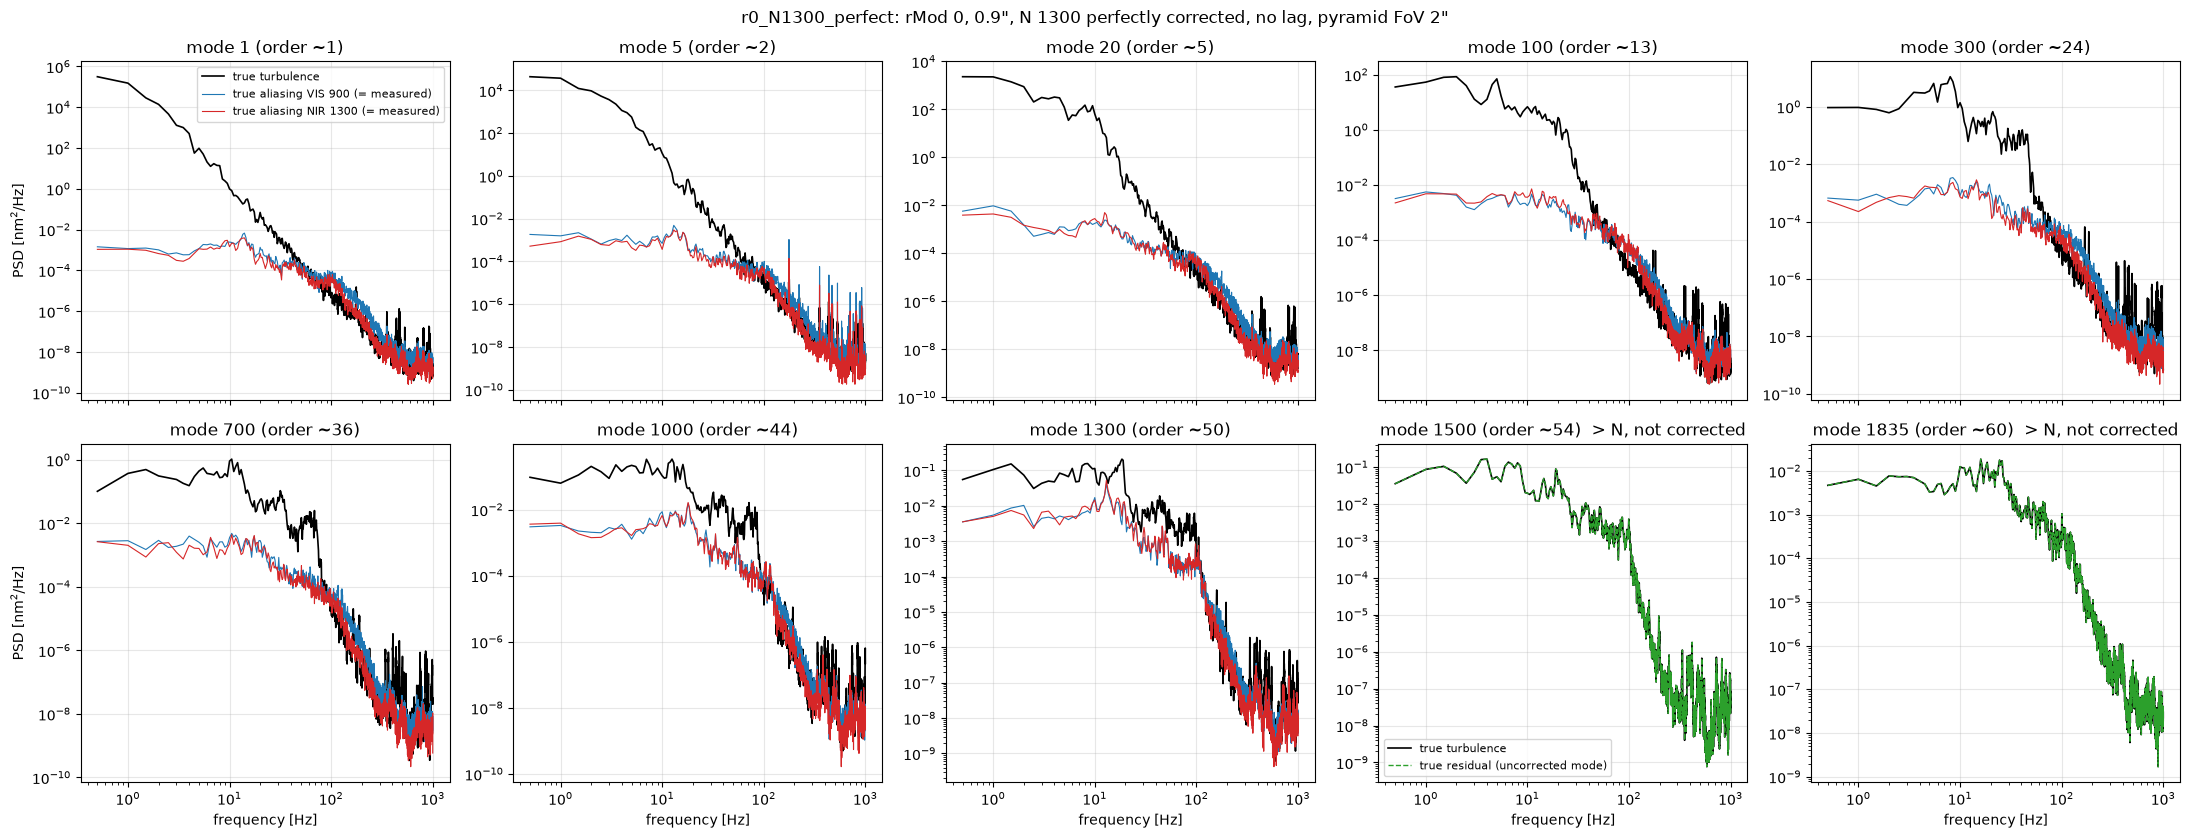

In [3]:
def psd_grid(name, modes=(0, 4, 19, 99, 299, 699, 999, 1299, 1499, 1834)):
    d = runs[name]
    N = d['N']
    perfect = 'perfect' in name
    f, S_turb = psd(d['true_turb'])
    _, S_res = psd(d['true_res'])
    S_alias = {cam: psd(d[f'true_alias_{cam}'])[1] for cam in ('vis', 'nir')}
    S_meas = {cam: psd(d[f'meas_{cam}'])[1] for cam in ('vis', 'nir')}
    modes = [j for j in modes if j < d['true_turb'].shape[1]]
    fig, axs = plt.subplots(2, 5, figsize=(22, 8.5), sharex=True)
    for ax, j in zip(axs.ravel(), modes):
        ax.loglog(f[1:], S_turb[1:, j], 'k', lw=1.2, label='true turbulence')
        if j < N:
            if not perfect:
                ax.loglog(f[1:], S_res[1:, j], 'C2', lw=1, label='true residual (Wiener level)')
                ax.loglog(f[1:], S_meas['vis'][1:, j], 'C9', lw=0.7, label='measured VIS 900')
                ax.loglog(f[1:], S_meas['nir'][1:, j], 'C1', lw=0.7, label='measured NIR 1300')
            lab = ' (= measured)' if perfect else ''
            ax.loglog(f[1:], S_alias['vis'][1:, j], 'C0', lw=0.8, label='true aliasing VIS 900' + lab)
            ax.loglog(f[1:], S_alias['nir'][1:, j], 'C3', lw=0.8, label='true aliasing NIR 1300' + lab)
        else:
            ax.loglog(f[1:], S_res[1:, j], 'C2--', lw=1, label='true residual (uncorrected mode)')
        ax.set_title(f'mode {j + 1} (order ~{radial_order(j)}){"  > N, not corrected" if j >= N else ""}')
        ax.grid(True, which='major', alpha=0.3)
    for ax in axs[1]:
        ax.set_xlabel('frequency [Hz]')
    for ax in axs[:, 0]:
        ax.set_ylabel('PSD [nm$^2$/Hz]')
    axs[0, 0].legend(fontsize=8)
    axs[1, -2].legend(fontsize=8)
    fig.suptitle(f'{name}: rMod 0, 0.9", N {N} {"perfectly corrected" if perfect else "at the Wiener-bound residual"}, no lag, pyramid FoV 2"')
    fig.tight_layout()


psd_grid('r0_N1300_perfect')

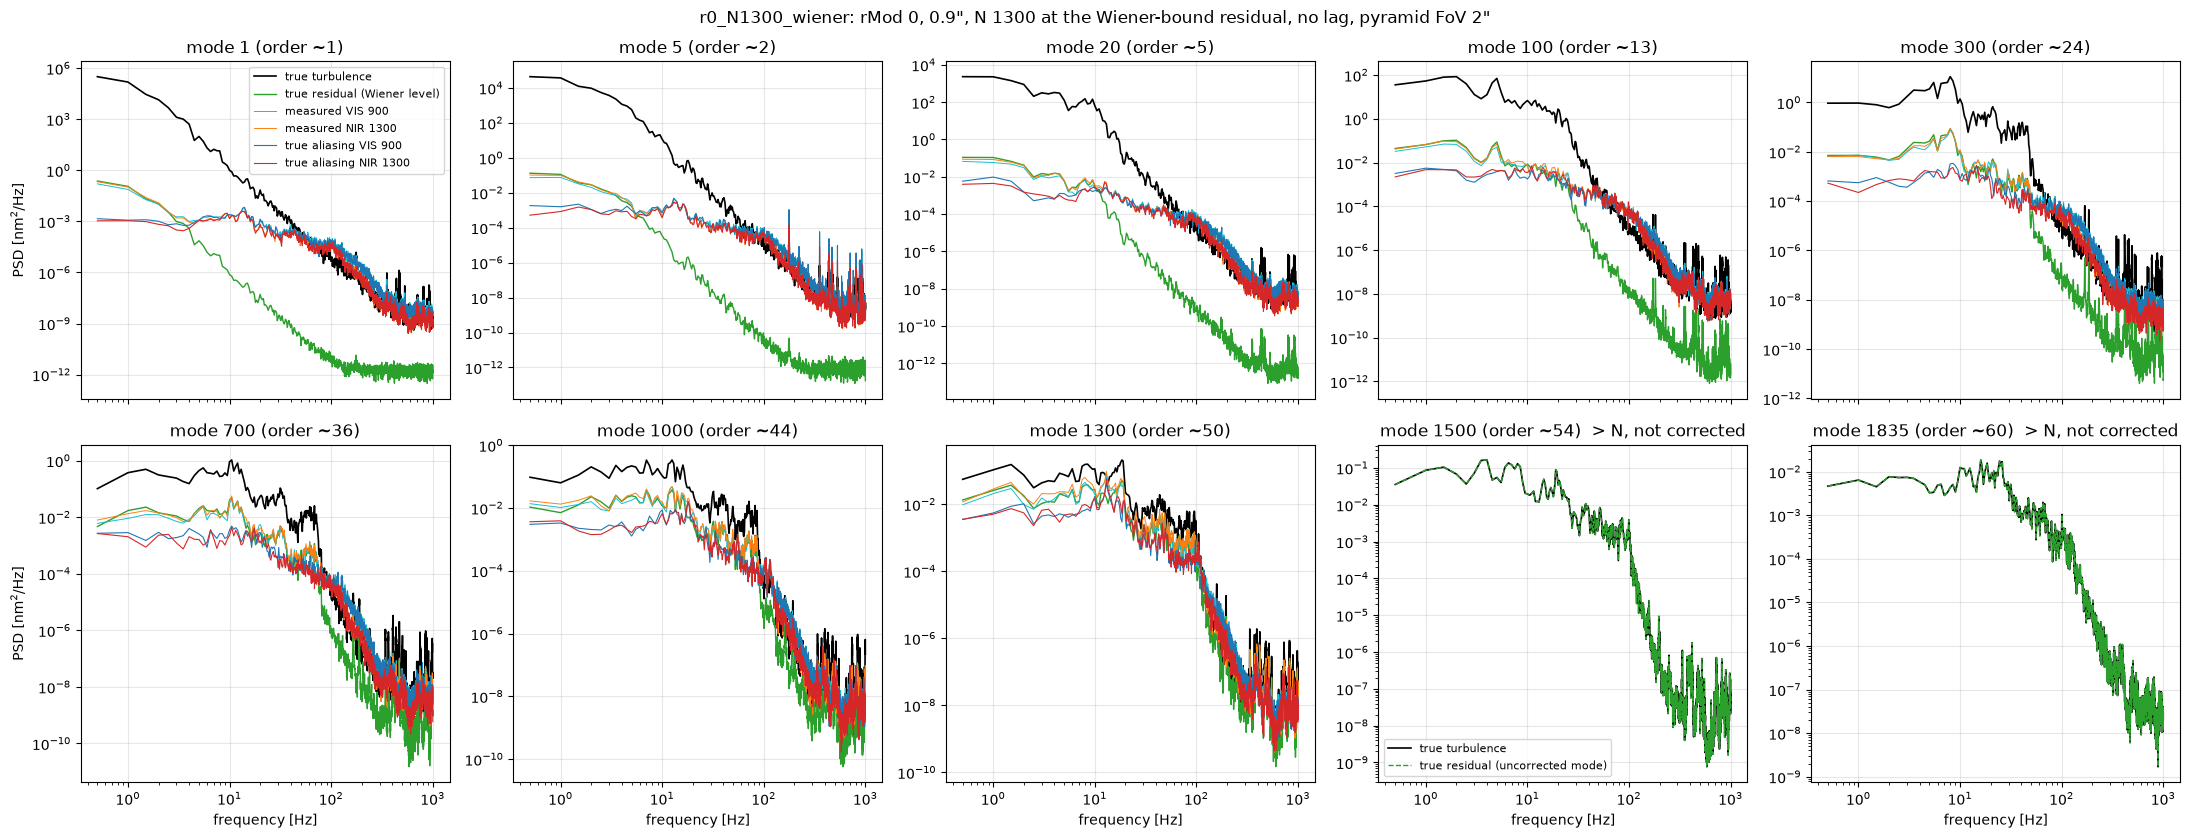

In [4]:
psd_grid('r0_N1300_wiener')

## Variance per mode, all runs: true aliasing and true residual

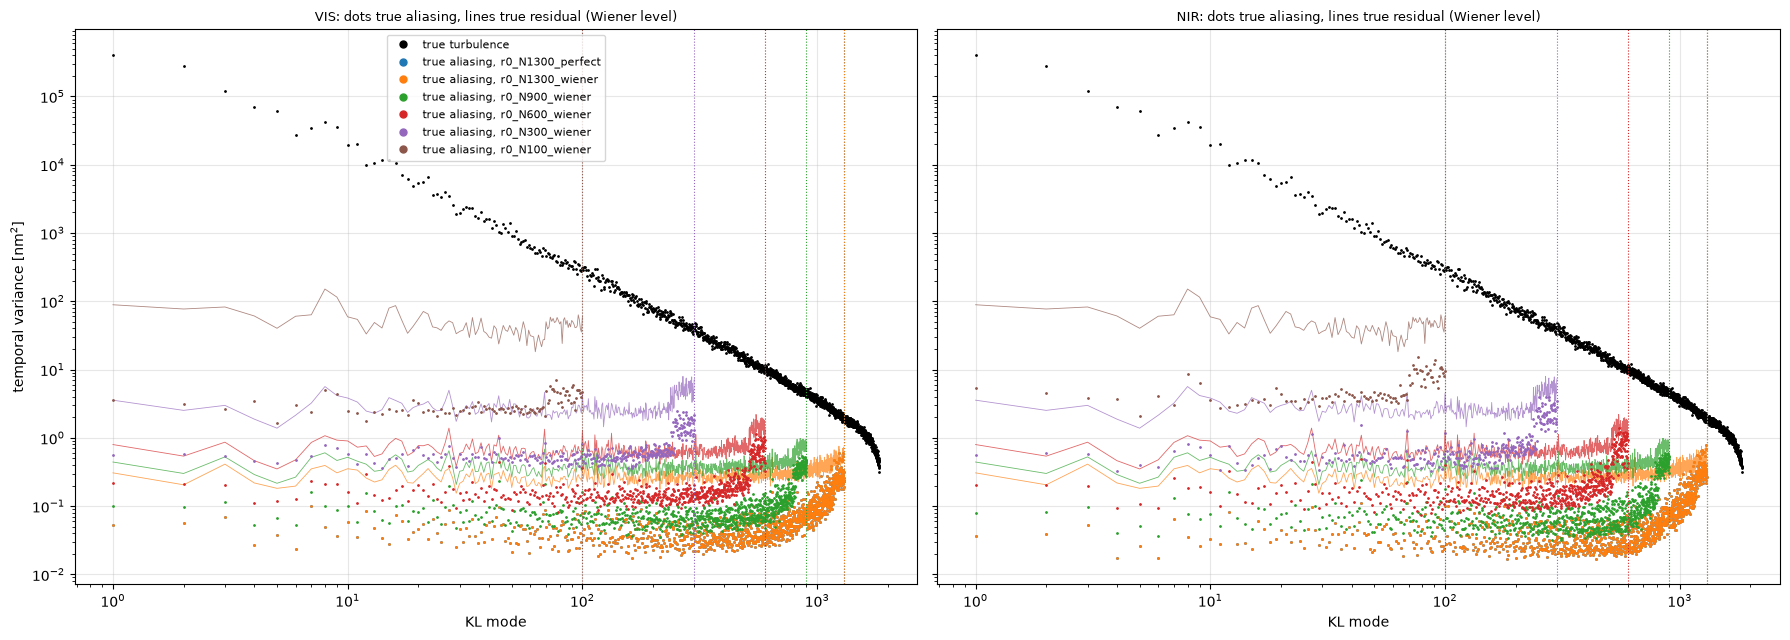

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(18, 6.5), sharey=True)
for ax, cam in zip(axs, ('vis', 'nir')):
    d0 = next(iter(runs.values()))
    j = np.arange(1, d0['true_turb'].shape[1] + 1)
    ax.loglog(j, d0['true_turb'].var(0), 'k.', ms=2, label='true turbulence')
    for k, (name, d) in enumerate(runs.items()):
        N = d['N']
        ax.loglog(j[:N], d[f'true_alias_{cam}'].var(0), '.', ms=2, color=f'C{k}', label=f'true aliasing, {name}')
        if 'wiener' in name:
            ax.loglog(j[:N], d['true_res'][:, :N].var(0), '-', lw=0.6, color=f'C{k}', alpha=0.7)
        ax.axvline(N, color=f'C{k}', ls=':', lw=0.8)
    ax.set_xlabel('KL mode')
    ax.set_title(f'{cam.upper()}: dots true aliasing, lines true residual (Wiener level)', fontsize=9)
    ax.grid(True, which='major', alpha=0.3)
axs[0].set_ylabel('temporal variance [nm$^2$]')
axs[0].legend(markerscale=5, fontsize=8)
fig.tight_layout()

## Measured vs true residual (optical gain) in the Wiener runs
`(meas - true aliasing)` regressed on `true_res` per mode: the pyramid's gain on the residual at that level (1 = linear, no OG loss).

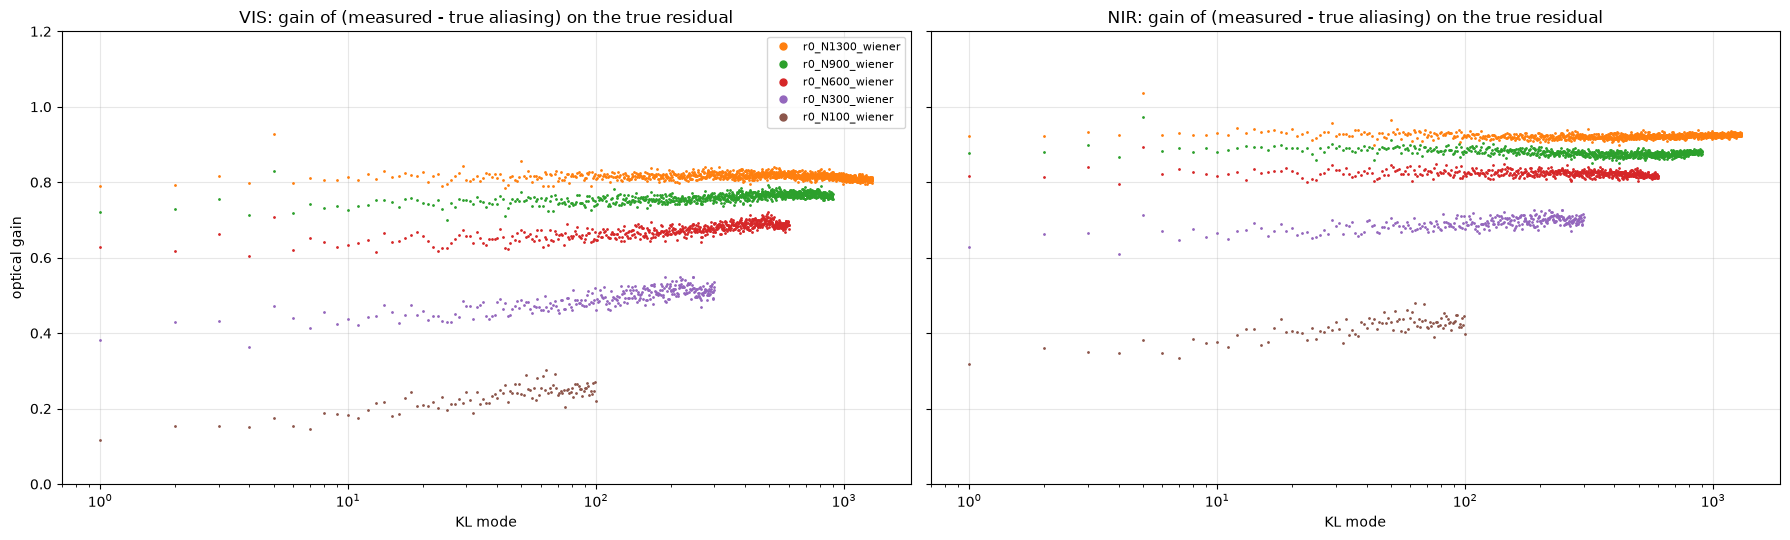

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(18, 5.5), sharey=True)
for ax, cam in zip(axs, ('vis', 'nir')):
    for k, (name, d) in enumerate(runs.items()):
        if 'wiener' not in name:
            continue
        N = d['N']
        r, y = d['true_res'][:, :N].astype(np.float64), d[f'meas_minus_alias_{cam}'].astype(np.float64)
        og = (r * y).sum(0) / (r * r).sum(0)
        ax.semilogx(np.arange(1, N + 1), og, color=f'C{k}', label=name)
    ax.set_xlabel('KL mode')
    ax.set_title(f'{cam.upper()}: gain of (measured - true aliasing) on the true residual')
    ax.grid(True, which='major', alpha=0.3)
axs[0].set_ylabel('optical gain')
axs[0].set_ylim(0, 1.2)
axs[0].legend(markerscale=5, fontsize=8)
fig.tight_layout()

## True aliasing PSD vs number of corrected modes (Wiener level), VIS and NIR

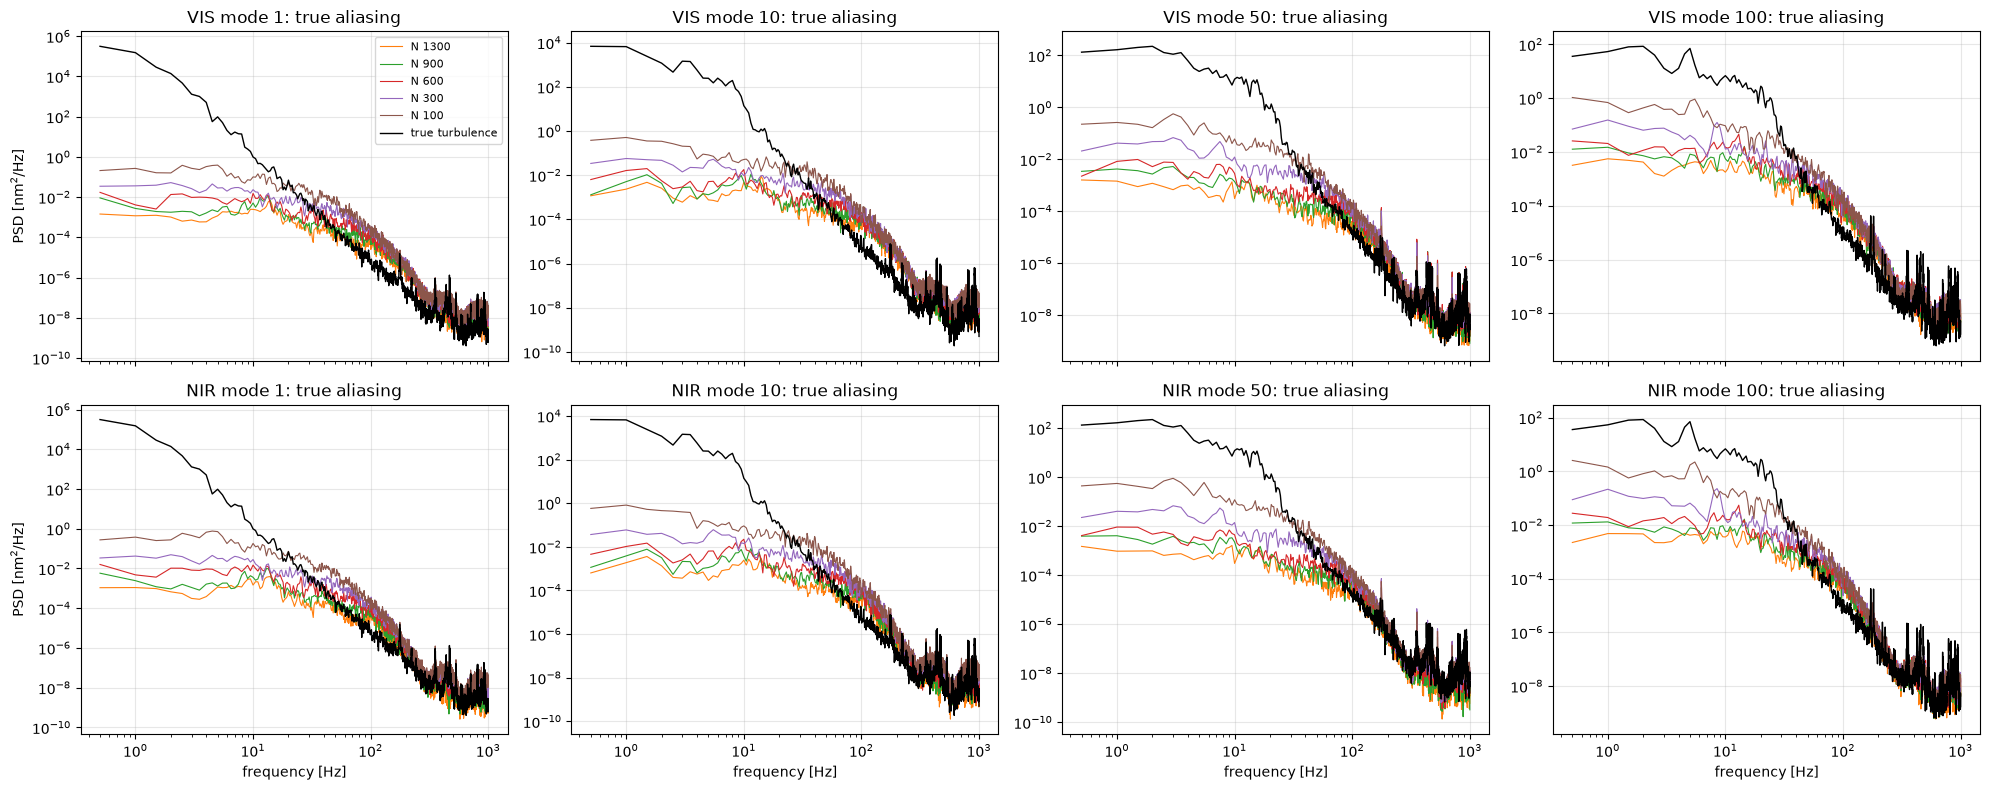

In [7]:
modes = (0, 9, 49, 99)                      # present in every run (N >= 100)
fig, axs = plt.subplots(2, len(modes), figsize=(20, 8), sharex=True)
for row, cam in enumerate(('vis', 'nir')):
    for ax, j in zip(axs[row], modes):
        for k, (name, d) in enumerate(runs.items()):
            if 'wiener' not in name:
                continue
            f, S = psd(d[f'true_alias_{cam}'][:, j])
            ax.loglog(f[1:], S[1:], lw=0.8, color=f'C{k}', label=f'N {d["N"]}')
        f, S = psd(next(iter(runs.values()))['true_turb'][:, j])
        ax.loglog(f[1:], S[1:], 'k', lw=1, label='true turbulence')
        ax.set_title(f'{cam.upper()} mode {j + 1}: true aliasing')
        ax.grid(True, which='major', alpha=0.3)
for ax in axs[1]:
    ax.set_xlabel('frequency [Hz]')
for ax in axs[:, 0]:
    ax.set_ylabel('PSD [nm$^2$/Hz]')
axs[0, 0].legend(fontsize=8)
fig.tight_layout()